<a href="https://colab.research.google.com/github/dasarisanjana9100/pothole_detection/blob/main/pothole_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics opencv-python-headless pandas matplotlib gradio

In [ ]:
import os
import cv2
import glob
import shutil
import torch
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from ultralytics import YOLO
from IPython.display import display, Video

print("Libraries imported successfully")

print("GPU available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Libraries imported successfully
GPU available: True


In [ ]:
import os
import zipfile
import requests
import shutil

url = (
    "https://www.dropbox.com/s/"
    "qvglw8pqo16769f/pothole_dataset_v8.zip?dl=1"
)

zip_path = "/content/pothole_dataset.zip"
dataset_path = "/content/pothole_dataset"

print("Downloading pothole dataset...")

response = requests.get(url, timeout=120)
response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

if not zipfile.is_zipfile(zip_path):
    os.remove(zip_path)
    raise ValueError(
        "The downloaded file is not a valid ZIP. "
        "Open the dataset link in your browser instead."
    )

if os.path.exists(dataset_path):
    shutil.rmtree(dataset_path)

os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(dataset_path)

print("Dataset downloaded and extracted successfully!")
print("Location:", dataset_path)

for root, dirs, filenames in os.walk(dataset_path):
    if "images" in root or root == dataset_path:
        print(root, "->", len(filenames), "files")

Dataset downloaded and extracted successfully!
Location: /content/pothole_dataset
/content/pothole_dataset -> 0 files
/content/pothole_dataset/pothole_dataset_v8/only_rainy_frames/train/images -> 348 files
/content/pothole_dataset/pothole_dataset_v8/train_to_valid/images -> 186 files
/content/pothole_dataset/pothole_dataset_v8/train/images -> 6962 files
/content/pothole_dataset/pothole_dataset_v8/valid/images -> 271 files


In [ ]:
import glob
import os

yaml_files = (
    glob.glob("/content/pothole_dataset/**/*.yaml",
              recursive=True)
    + glob.glob("/content/pothole_dataset/**/*.yml",
                recursive=True)
)

if yaml_files:
    data_yaml = yaml_files[0]
    print("Configuration file:", data_yaml)

    with open(data_yaml, "r") as f:
        print(f.read())
else:
    print("No YAML file found. Check the extracted folders.")

Configuration file: /content/pothole_dataset/pothole_dataset_v8/pothole.yaml
train: train/images 
val: valid/images 

nc: 1

# Classes
names: ['pothole']



In [ ]:
!pip install -q roboflow

from roboflow import Roboflow

# Connect to Roboflow
rf = Roboflow(api_key="AEgsPfX09VkY73IUs1gz")

# Access the public pothole dataset
project = rf.workspace("gerapothole").project(
    "pothole-detection-yolov8"
)

# Download dataset in YOLOv8 format
dataset = project.version(1).download(
    "yolov8",
    location="/content/pothole_dataset"
)

data_yaml = dataset.location + "/data.yaml"

print("Dataset downloaded successfully!")
print("Dataset configuration:", data_yaml)

loading Roboflow workspace...
loading Roboflow project...
Dataset downloaded successfully!
Dataset configuration: /content/pothole_dataset/data.yaml


In [ ]:
import os

print("Checking downloaded dataset...")

for folder in [
    "/content/pothole_dataset",
    "/content",
]:
    print(f"\nFolder: {folder}")

    if os.path.exists(folder):
        print(os.listdir(folder)[:30])
    else:
        print("Folder does not exist")

Checking downloaded dataset...

Folder: /content/pothole_dataset
['pothole_dataset_v8']

Folder: /content
['.config', 'pothole_dataset.zip', 'pothole_dataset', 'sample_data']


In [ ]:
!pip -q install -U huggingface_hub

from huggingface_hub import snapshot_download
import os
import glob

dataset_path = "/content/pothole_dataset"

print("Downloading public pothole dataset...")

snapshot_download(
    repo_id="Ryukijano/Pothole-detection-Yolov8",
    repo_type="dataset",
    local_dir=dataset_path
)

yaml_files = glob.glob(
    dataset_path + "/**/data.yaml",
    recursive=True
)

if yaml_files:
    data_yaml = yaml_files[0]

    print("Dataset downloaded successfully!")
    print("Configuration:", data_yaml)

    with open(data_yaml, "r") as f:
        print(f.read())
else:
    print("data.yaml was not found. Check the dataset files.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 605 files:   0%|          | 0/605 [00:00<?, ?it/s]

Dataset downloaded successfully!
Configuration: /content/pothole_dataset/data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['0']

roboflow:
  workspace: project-ssayl
  project: potholes-detection-d4rma
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/project-ssayl/potholes-detection-d4rma/dataset/1


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data=data_yaml,
    epochs=30,
    imgsz=640,
    batch=8,
    project="/content/pothole_project",
    name="pothole_detector"
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pothole_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pothole_detector, nbs=64, nms=None, opset=None, optimize

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c75381e44b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
import os

best_model_path = (
    "/content/pothole_project/"
    "pothole_detector/weights/best.pt"
)

if os.path.exists(best_model_path):
    print("Model training completed successfully!")
    print("Trained model:", best_model_path)
else:
    print("Trained model not found.")
    print("Complete the dataset download and training steps first.")

Model training completed successfully!
Trained model: /content/pothole_project/pothole_detector/weights/best.pt


In [ ]:
from ultralytics import YOLO

model = YOLO(best_model_path)

metrics = model.val(
    data=data_yaml,
    imgsz=640
)

print("Model Evaluation Results")
print("------------------------")
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))
print("mAP@0.5:", round(metrics.box.map50, 4))
print("mAP@0.5:0.95:", round(metrics.box.map, 4))

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1345.8±519.5 MB/s, size: 59.2 KB)
val: Scanning /content/pothole_dataset/valid/labels.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 32.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.8it/s 3.8s
                   all        100        286       0.51      0.374      0.379      0.156
Speed: 5.1ms preprocess, 8.8ms inference, 0.0ms loss, 4.2ms postprocess per image
Results saved to /content/runs/detect/val
Model Evaluation Results
------------------------
Precision: 0.5102
Recall: 0.3741
mAP@0.5: 0.3793
mAP@0.5:0.95: 0.1562


Image selected automatically: /content/pothole_dataset/train/images/0059_jpg.rf.1468d3c6e4b89da5684ea5ee45d2feb2.jpg

image 1/1 /content/pothole_dataset/train/images/0059_jpg.rf.1468d3c6e4b89da5684ea5ee45d2feb2.jpg: 640x640 5 0s, 13.3ms
Speed: 1.6ms preprocess, 13.3ms inference, 2.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


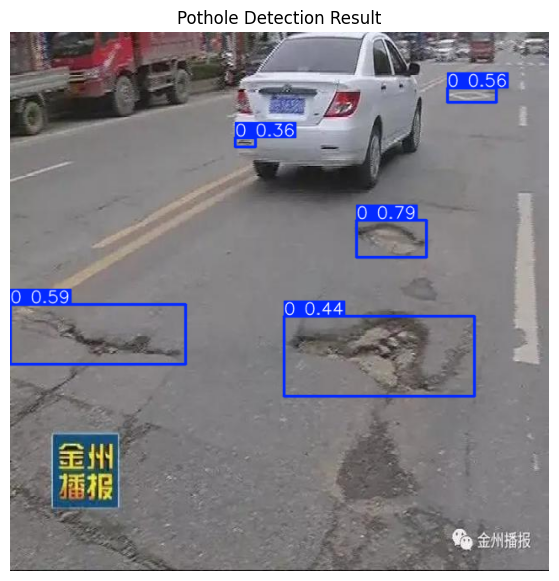

Potholes detected: 5


In [ ]:
import glob
import os
import cv2
import matplotlib.pyplot as plt

# Find images in the downloaded dataset
image_files = []

for ext in ["jpg", "jpeg", "png"]:
    image_files.extend(
        glob.glob(
            f"/content/pothole_dataset/**/*.{ext}",
            recursive=True
        )
    )

# Exclude images from validation and test labels if needed
image_files = [
    path for path in image_files
    if "/images/" in path.replace("\\", "/")
]

if len(image_files) == 0:
    print("No dataset images found.")
    print("Please check whether your dataset downloaded successfully.")

else:
    # Automatically select an image
    image_path = image_files[0]

    print("Image selected automatically:", image_path)

    # Load the trained model if necessary
    model_path = (
        "/content/pothole_project/"
        "pothole_detector/weights/best.pt"
    )

    from ultralytics import YOLO

    if os.path.exists(model_path):
        model = YOLO(model_path)
    else:
        print("Trained model not found. Train the model first.")

    if os.path.exists(model_path):
        # Detect potholes
        results = model.predict(
            source=image_path,
            conf=0.25,
            save=True
        )

        # Display the result
        result_image = results[0].plot()
        result_image = cv2.cvtColor(
            result_image,
            cv2.COLOR_BGR2RGB
        )

        plt.figure(figsize=(10, 7))
        plt.imshow(result_image)
        plt.title("Pothole Detection Result")
        plt.axis("off")
        plt.show()

        print(
            "Potholes detected:",
            len(results[0].boxes)
        )

In [ ]:
import requests
import os

video_url = (
    "https://github.com/intel-iot-devkit/sample-videos/"
    "raw/master/people-detection.mp4"
)

video_path = "/content/road_video.mp4"

response = requests.get(video_url, timeout=120)
response.raise_for_status()

with open(video_path, "wb") as f:
    f.write(response.content)

print("Sample video downloaded successfully!")
print("Video location:", video_path)

Sample video downloaded successfully!
Video location: /content/road_video.mp4


In [ ]:
import cv2
import pandas as pd

cap = cv2.VideoCapture(video_path)

frame_number = 0
report = []

while True:
    ret, frame = cap.read()

    if not ret:
        break

    # Process every second frame
    if frame_number % 2 == 0:
        prediction = model.predict(
            source=frame,
            conf=0.25,
            verbose=False
        )

        pothole_count = len(prediction[0].boxes)

        report.append({
            "Frame_Number": frame_number,
            "Potholes_Detected": pothole_count
        })

    frame_number += 1

cap.release()

df = pd.DataFrame(report)

df.to_csv(
    "/content/road_maintenance_report.csv",
    index=False
)

print("Road-maintenance report created!")
display(df.head(10))

Road-maintenance report created!


,Frame_Number,Potholes_Detected
0,0,0
1,2,0
2,4,0
3,6,0
4,8,0
5,10,0
6,12,0
7,14,0
8,16,0
9,18,0


In [ ]:
from google.colab import files

files.download("/content/road_maintenance_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import glob

# Check dataset
dataset_path = "/content/pothole_dataset"

print("========== DATASET STATUS ==========")

if os.path.exists(dataset_path):
    print("Dataset folder exists.")

    images = []
    for ext in ["jpg", "jpeg", "png"]:
        images.extend(
            glob.glob(
                f"{dataset_path}/**/*.{ext}",
                recursive=True
            )
        )

    print("Number of images found:", len(images))
else:
    print("Dataset folder not found.")

# Check dataset configuration
yaml_files = glob.glob(
    "/content/pothole_dataset/**/*.yaml",
    recursive=True
)

if yaml_files:
    data_yaml = yaml_files[0]
    print("Dataset configuration:", data_yaml)
else:
    print("Dataset configuration file not found.")

# Check trained model
model_path = (
    "/content/pothole_project/"
    "pothole_detector/weights/best.pt"
)

print("\n========== MODEL STATUS ==========")

if os.path.exists(model_path):
    print("Trained model is ready!")
else:
    print("Trained model not found. Training may not be completed.")

# Check downloaded video
video_path = "/content/road_video.mp4"

print("\n========== VIDEO STATUS ==========")

if os.path.exists(video_path):
    print("Video downloaded successfully!")
else:
    print("Video not found.")

========== DATASET STATUS ==========
Dataset folder exists.
Number of images found: 8067
Dataset configuration: /content/pothole_dataset/data.yaml

========== MODEL STATUS ==========
Trained model is ready!

========== VIDEO STATUS ==========
Video downloaded successfully!


Testing image: /content/pothole_dataset/train/images/0059_jpg.rf.1468d3c6e4b89da5684ea5ee45d2feb2.jpg

image 1/1 /content/pothole_dataset/train/images/0059_jpg.rf.1468d3c6e4b89da5684ea5ee45d2feb2.jpg: 640x640 5 0s, 6.0ms
Speed: 1.0ms preprocess, 6.0ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-2


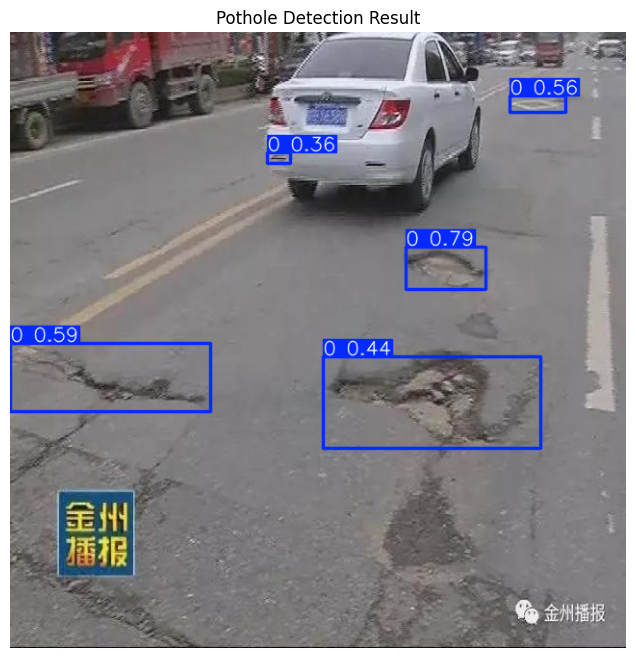

Number of potholes/objects detected: 5


In [ ]:
import os
import glob
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load the trained model
model_path = "/content/pothole_project/pothole_detector/weights/best.pt"
model = YOLO(model_path)

# Find an image from the downloaded dataset
image_files = []

for ext in ["jpg", "jpeg", "png"]:
    image_files.extend(
        glob.glob(f"/content/pothole_dataset/**/*.{ext}", recursive=True)
    )

# Select an image automatically
if len(image_files) > 0:
    image_path = image_files[0]
    print("Testing image:", image_path)

    # Detect potholes
    results = model.predict(
        source=image_path,
        conf=0.25,
        save=True
    )

    # Display the detection result
    result_image = results[0].plot()
    result_image = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 8))
    plt.imshow(result_image)
    plt.title("Pothole Detection Result")
    plt.axis("off")
    plt.show()

    # Display the number of detected objects
    print("Number of potholes/objects detected:", len(results[0].boxes))

else:
    print("No images found in the dataset.")

Video opened: True
Video duration (seconds): 49.67


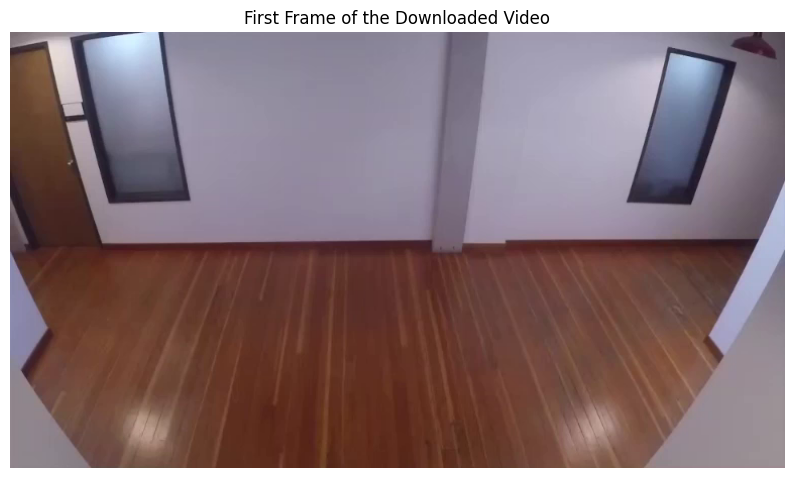

In [ ]:
import cv2
import os
from IPython.display import display, Video

video_path = "/content/road_video.mp4"

if os.path.exists(video_path):
    cap = cv2.VideoCapture(video_path)

    print("Video opened:", cap.isOpened())
    print("Video duration (seconds):",
          round(cap.get(cv2.CAP_PROP_FRAME_COUNT) /
                max(cap.get(cv2.CAP_PROP_FPS), 1), 2))

    ret, frame = cap.read()

    if ret:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        import matplotlib.pyplot as plt

        plt.figure(figsize=(10, 6))
        plt.imshow(frame)
        plt.title("First Frame of the Downloaded Video")
        plt.axis("off")
        plt.show()

    cap.release()
else:
    print("Video file not found.")

In [ ]:
import requests

video_url = "https://github.com/Vikaash-dev/road-anomaly-detection-ai/raw/refs/heads/main/demo1.mp4"

response = requests.get(video_url, timeout=60)

if response.status_code == 200 and len(response.content) > 10000:
    with open("/content/road_video.mp4", "wb") as f:
        f.write(response.content)

    print("Video downloaded successfully!")
    print("File size:", round(len(response.content) / (1024 * 1024), 2), "MB")
else:
    print("Download failed. Open the repository link above and check the video filename.")

Video downloaded successfully!
File size: 15.09 MB


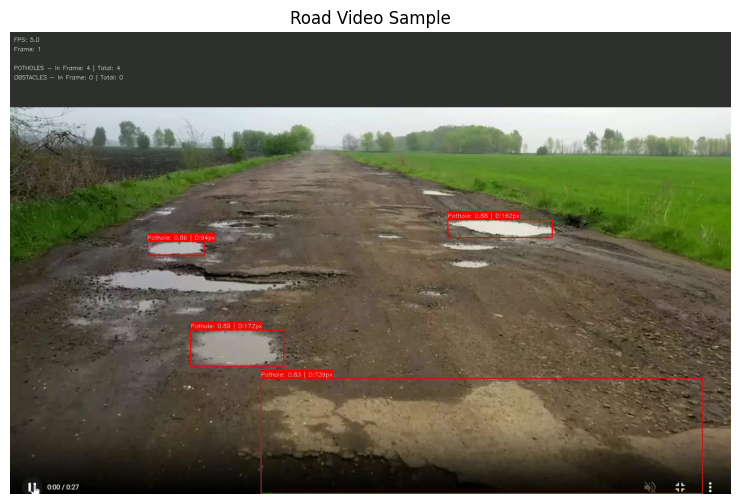

In [ ]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture("/content/road_video.mp4")

ret, frame = cap.read()

if ret:
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(frame)
    plt.title("Road Video Sample")
    plt.axis("off")
    plt.show()
else:
    print("Unable to read the video. Please check the download.")

cap.release()

In [ ]:
import os
import cv2
from ultralytics import YOLO
from IPython.display import display, Video

# Step 1: Load the trained model
model_path = "/content/pothole_project/pothole_detector/weights/best.pt"
video_path = "/content/road_video.mp4"

if not os.path.exists(model_path):
    print("Trained model not found. Check the model path.")

elif not os.path.exists(video_path):
    print("Video not found. Please download the video first.")

else:
    model = YOLO(model_path)

    # Step 2: Open the video
    cap = cv2.VideoCapture(video_path)

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if not cap.isOpened() or fps <= 0:
        print("Unable to open the video.")

    else:
        # Step 3: Create output video
        output_path = "/content/pothole_detection_output.mp4"

        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        out = cv2.VideoWriter(
            output_path, fourcc, fps, (width, height)
        )

        total_detections = 0
        frames_processed = 0

        # Step 4: Detect objects in each frame
        while True:
            ret, frame = cap.read()

            if not ret:
                break

            results = model.predict(
                source=frame,
                conf=0.25,
                verbose=False
            )

            annotated_frame = results[0].plot()
            out.write(annotated_frame)

            total_detections += len(results[0].boxes)
            frames_processed += 1

            if frames_processed % 100 == 0:
                print("Frames processed:", frames_processed)

        # Step 5: Release resources
        cap.release()
        out.release()

        print("\nVideo processing completed!")
        print("Total frames processed:", frames_processed)
        print("Total detections across frames:", total_detections)
        print("Output saved at:", output_path)

        # Step 6: Display the processed video
        if frames_processed > 0:
            display(Video(output_path, embed=True))

In [ ]:
from IPython.display import display, Video
import os

video_path = "/content/pothole_detection_output.mp4"

if os.path.exists(video_path):
    print("Output video size:",
          round(os.path.getsize(video_path) / (1024 * 1024), 2),
          "MB")

    display(Video(video_path, embed=True, html_attributes="controls"))
else:
    print("Output video not found. Run the video detection code again.")

In [ ]:
import subprocess
import os

input_video = "/content/pothole_detection_output.mp4"
output_video = "/content/pothole_detection_final.mp4"

result = subprocess.run([
    "ffmpeg", "-y",
    "-i", input_video,
    "-vcodec", "libx264",
    "-pix_fmt", "yuv420p",
    "-acodec", "aac",
    "-movflags", "+faststart",
    output_video
], capture_output=True, text=True)

if result.returncode == 0:
    print("Video converted successfully!")
else:
    print(result.stderr[-2000:])

Video converted successfully!


In [ ]:
from IPython.display import Video, display

display(Video(
    "/content/pothole_detection_final.mp4",
    embed=True,
    html_attributes="controls"
))

In [ ]:
from google.colab import files

files.download("/content/pothole_detection_final.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>